# Q12: Data Aggregation

**Problem Statement:** Analyzing Sales Performance by Region in a Retail Company

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

retail = pd.read_csv("Retail_Sales_Data.csv", parse_dates=["TransactionDate"])
print("Transactions:", len(retail))
print(retail.head().to_string(index=False))
print("Regions:", sorted(retail["Region"].unique()))


Transactions: 320
TransactionID TransactionDate Region ProductCategory  QuantitySold  UnitPrice  SalesAmount
       RS0001      2025-05-06  North     Electronics             5   13052.75     65263.75
       RS0002      2025-05-17  South     Electronics             3   17059.11     51177.33
       RS0003      2025-01-05  North       Groceries             3     401.71      1205.13
       RS0004      2025-01-27   West       Groceries             1     534.48       534.48
       RS0005      2025-02-22  North     Electronics             1   12518.23     12518.23
Regions: ['East', 'North', 'South', 'West']


In [2]:
# Total sales and transaction counts by region.
by_region = retail.groupby("Region").agg(TotalSales=("SalesAmount", "sum"), Transactions=("TransactionID", "count"))
by_region = by_region.sort_values("TotalSales", ascending=False)
print(by_region.round(2).to_string())
print("Top-performing region:", by_region.index[0])


        TotalSales  Transactions
Region                          
East    1698905.09            91
South   1377072.57            81
West    1284922.31            76
North   1076181.45            72
Top-performing region: East


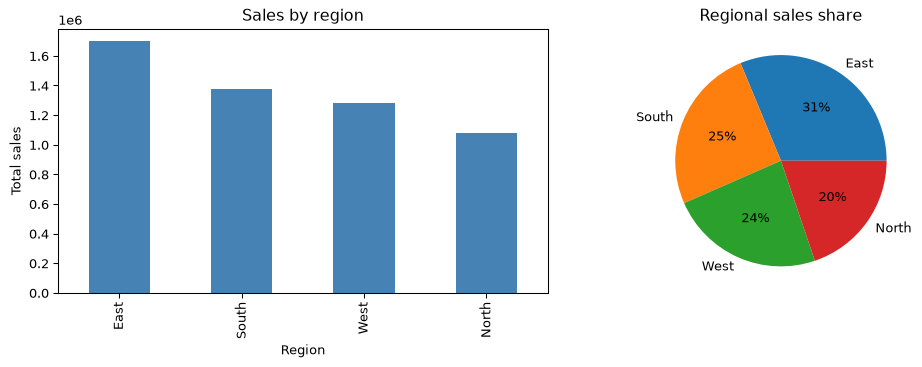

In [3]:
# Compare the regional distribution as both bars and shares.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_region["TotalSales"].plot.bar(ax=axes[0], title="Sales by region", color="steelblue")
axes[0].set_ylabel("Total sales")
by_region["TotalSales"].plot.pie(ax=axes[1], title="Regional sales share", autopct="%1.0f%%")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()


ProductCategory   Clothing  Electronics  Furniture  Groceries
Region                                                       
East             170426.18   1181603.03  324492.99   22382.89
North             88969.85    610659.57  354800.79   21751.24
South            130530.86    835316.94  387559.17   23665.60
West             173872.12    736480.36  357921.97   16647.86


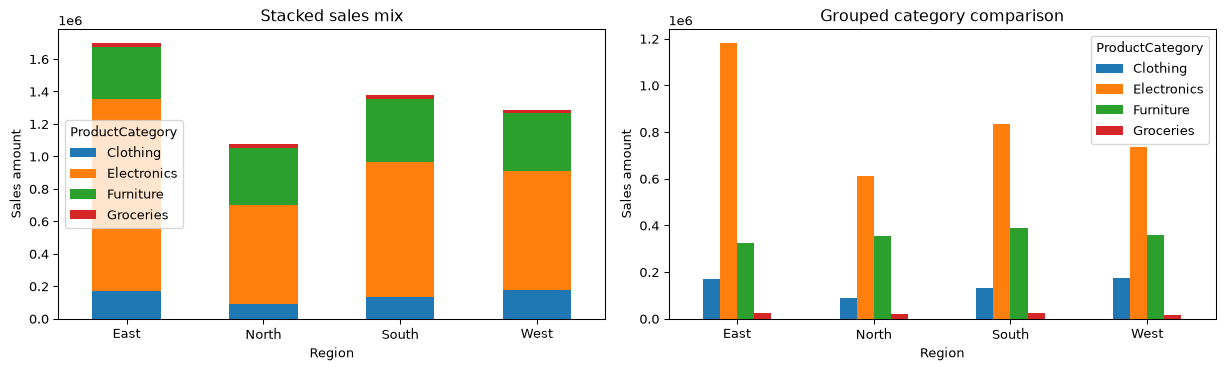

In [4]:
# Group by both region and product category to expose the sales mix.
regional_category = retail.pivot_table(index="Region", columns="ProductCategory", values="SalesAmount", aggfunc="sum", fill_value=0)
print(regional_category.round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
regional_category.plot.bar(stacked=True, ax=axes[0], title="Stacked sales mix")
regional_category.plot.bar(ax=axes[1], title="Grouped category comparison")
for axis in axes:
    axis.set_ylabel("Sales amount")
    axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
